In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from network_SIR import make_network, run_sir, run_many, NET_COLORS

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
n = 374
k = 6
gamma = 0.1
n_instances = 5
n_runs = 10

networks = {}
for kind in ["ER", "WS", "BA"]:
    networks[kind] = [make_network(kind, n, k, seed=i) for i in range(n_instances)]


def pad(arr, length):
    if len(arr) >= length:
        return arr[:length]
    return np.pad(arr, (0, length - len(arr)), mode="edge")

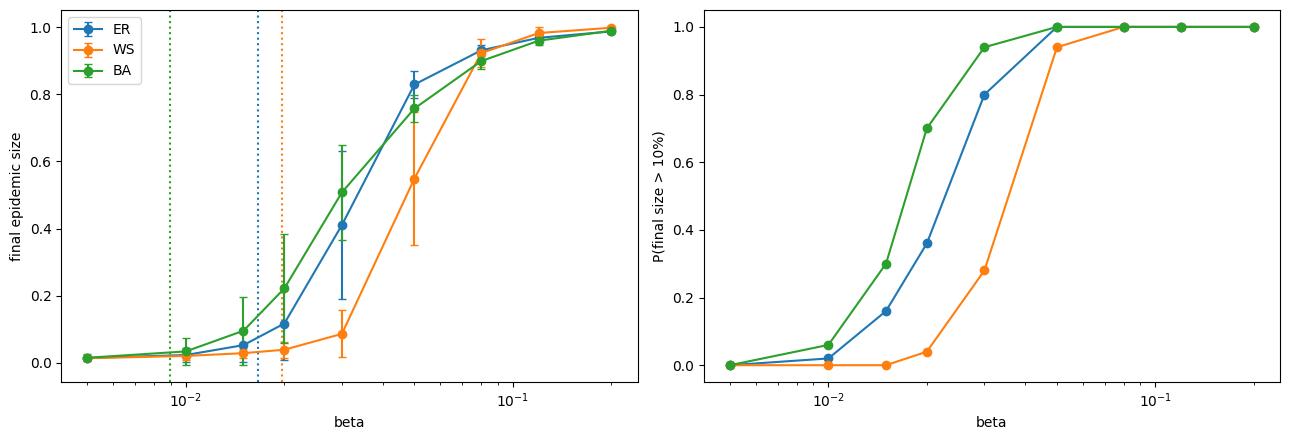

In [4]:
betas = [0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.08, 0.12, 0.2]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for kind in ["ER", "WS", "BA"]:
    mean_final = []
    std_final = []
    p_major = []
    for beta in betas:
        final_sizes = []
        for i, G in enumerate(networks[kind]):
            results = run_many(G, beta, gamma, n_init=4, n_runs=n_runs, seed=100 * i)
            final_sizes += [R[-1] for S, I, R in results]
        final_sizes = np.array(final_sizes)
        mean_final.append(np.mean(final_sizes))
        std_final.append(np.std(final_sizes))
        p_major.append(np.mean(final_sizes > 0.1))

    axes[0].errorbar(betas, mean_final, yerr=std_final, marker="o", capsize=3,
                     color=NET_COLORS[kind], label=kind)
    axes[1].plot(betas, p_major, marker="o", color=NET_COLORS[kind], label=kind)

    deg = np.array([d for G in networks[kind] for node, d in G.degree()])
    beta_c = gamma * np.mean(deg) / (np.mean(deg**2) - np.mean(deg))
    axes[0].axvline(beta_c, color=NET_COLORS[kind], linestyle=":")

axes[0].set_xscale("log")
axes[0].set_xlabel("beta")
axes[0].set_ylabel("final epidemic size")
axes[0].legend()
axes[1].set_xscale("log")
axes[1].set_xlabel("beta")
axes[1].set_ylabel("P(final size > 10%)")
plt.tight_layout()
plt.savefig("figures/final_size_vs_beta.png", dpi=200, bbox_inches="tight")
plt.show()

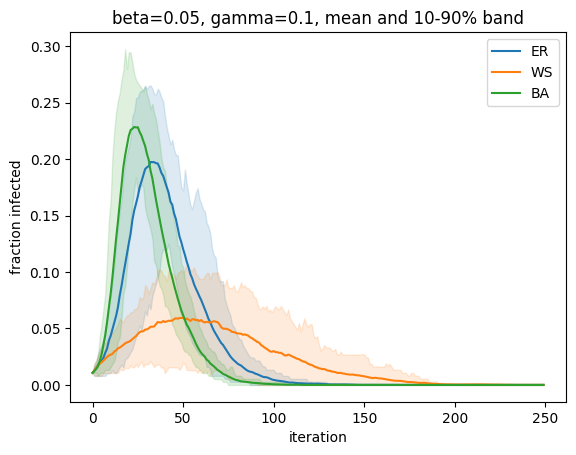

In [8]:
beta = 0.05
T = 250

for kind in ["ER", "WS", "BA"]:
    curves = []
    for i, G in enumerate(networks[kind]):
        results = run_many(G, beta, gamma, n_init=4, n_runs=n_runs, seed=100 * i)
        curves += [pad(I, T) for S, I, R in results]
    curves = np.array(curves)

    plt.plot(curves.mean(axis=0), color=NET_COLORS[kind], label=kind)
    plt.fill_between(range(T), np.percentile(curves, 10, axis=0), np.percentile(curves, 90, axis=0),
                     color=NET_COLORS[kind], alpha=0.15)

plt.xlabel("iteration")
plt.ylabel("fraction infected")
plt.title(f"beta={beta}, gamma={gamma}, mean and 10-90% band")
plt.legend()
plt.savefig("figures/epidemic_curves.png", dpi=200, bbox_inches="tight")
plt.show()

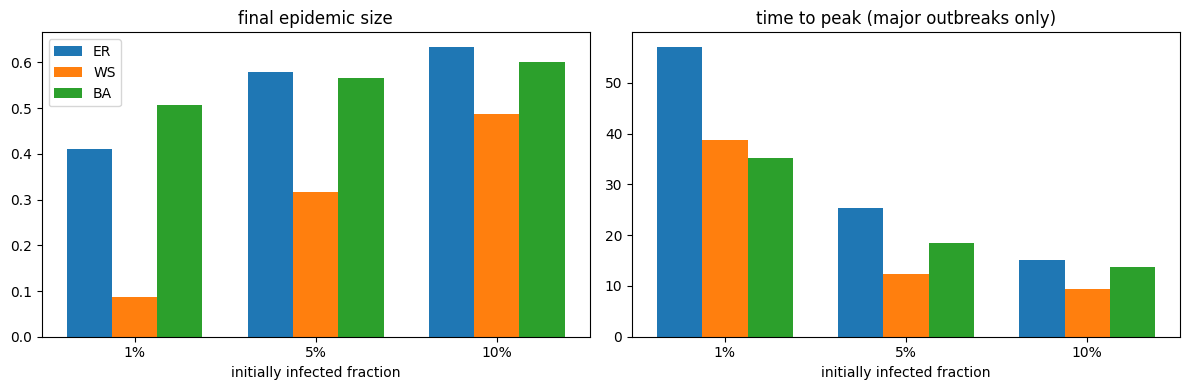

In [13]:
beta = 0.03
fractions = [0.01, 0.05, 0.10]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(fractions))

for j, kind in enumerate(["ER", "WS", "BA"]):
    mean_final = []
    mean_tpeak = []
    for f in fractions:
        n_init = int(round(f * n))
        finals = []
        tpeaks = []
        for i, G in enumerate(networks[kind]):
            results = run_many(G, beta, gamma, n_init=n_init, n_runs=n_runs, seed=100 * i)
            finals += [R[-1] for S, I, R in results]
            tpeaks += [np.argmax(I) for S, I, R in results if R[-1] - f > 0.1]
        mean_final.append(np.mean(finals))
        mean_tpeak.append(np.mean(tpeaks))

    axes[0].bar(x + (j - 1) * 0.25, mean_final, 0.25, color=NET_COLORS[kind], label=kind)
    axes[1].bar(x + (j - 1) * 0.25, mean_tpeak, 0.25, color=NET_COLORS[kind], label=kind)

for ax, title in zip(axes, ["final epidemic size", "time to peak (major outbreaks only)"]):
    ax.set_xticks(x)
    ax.set_xticklabels([f"{int(f * 100)}%" for f in fractions])
    ax.set_xlabel("initially infected fraction")
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()
plt.savefig("figures/initial_fraction.png", dpi=200, bbox_inches="tight")
plt.show()

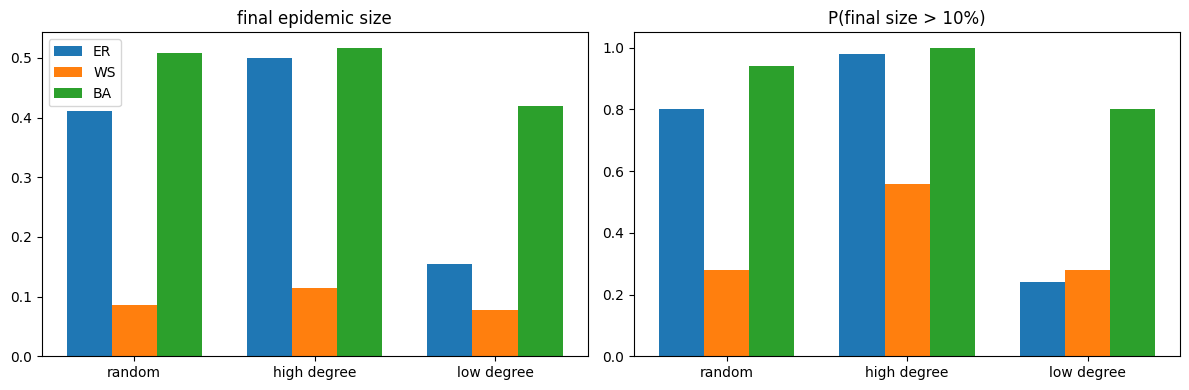

In [14]:
beta = 0.03
n_init = 4
rules = ["random", "high degree", "low degree"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(rules))

for j, kind in enumerate(["ER", "WS", "BA"]):
    mean_final = []
    p_major = []
    for rule in rules:
        finals = []
        for i, G in enumerate(networks[kind]):
            degrees = np.array([d for node, d in G.degree()])
            for r in range(n_runs):
                rng = np.random.default_rng(100 * i + r)
                if rule == "random":
                    initial = rng.choice(n, size=n_init, replace=False)
                elif rule == "high degree":
                    initial = np.lexsort((rng.random(n), -degrees))[:n_init]
                else:
                    initial = np.lexsort((rng.random(n), degrees))[:n_init]
                S, I, R = run_sir(G, beta, gamma, initial, seed=100 * i + r)
                finals.append(R[-1])
        finals = np.array(finals)
        mean_final.append(np.mean(finals))
        p_major.append(np.mean(finals > 0.1))

    axes[0].bar(x + (j - 1) * 0.25, mean_final, 0.25, color=NET_COLORS[kind], label=kind)
    axes[1].bar(x + (j - 1) * 0.25, p_major, 0.25, color=NET_COLORS[kind], label=kind)

for ax, title in zip(axes, ["final epidemic size", "P(final size > 10%)"]):
    ax.set_xticks(x)
    ax.set_xticklabels(rules)
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()
plt.savefig("figures/initial_nodes.png", dpi=200, bbox_inches="tight")
plt.show()